# Lab 00 — First steps in mass and heat balances

Learn to choose a system boundary, label streams, state assumptions and write
balances before calculating. You need basic arithmetic and algebra; no prior
balance course or Python programming is assumed. All case values are synthetic.

**Workload:** about three hours of core work, including a short break. Optional
practice can extend this to four–six hours; it is an introduction rather than
another advanced design lab. Work in pairs. Show equations, substituted numbers
and units. Calculations are supplied so the focus remains on setting up balances.

Submit your completed answer cells and a short explanation (150–250 words) of
how you distinguish a mass balance, component balance and energy balance.

## 1. The balance recipe — 30 minutes

1. Draw the boundary: what equipment or volume is inside?
2. Label inputs, outputs and stored quantities. Write units beside each.
3. State assumptions: steady or changing inventory? Reaction? Heat loss?
4. Write the symbolic balance before inserting values; count unknowns.
5. Calculate and check units, conservation and physically sensible limits.

For a nonreacting system:

$$\text{accumulation rate}=\text{rate in}-\text{rate out}.$$

Total mass is conserved. For a component, include production/consumption if
there is reaction; all examples here are nonreacting. At steady state,
accumulation is zero. An energy balance also includes energy transferred as
heat or work across the boundary. The terms depend on the chosen boundary.

**Do not confuse:** kg (inventory) with kg/s (flow); mass fraction with mass
flow; kW (power) with kWh (energy). A balance residual of zero checks arithmetic
and consistency, but does not prove the assumptions match real equipment.

**Data convention:** Numbers stated in each problem are supplied inputs or
explicit assumptions; outlet properties and duties are calculated results.
The salt fractions are kg salt/kg solution. Drawings show the printed default
case; when changing a setting, update your own stream labels accordingly.

**Prediction:** If water is added to a salt solution without salt loss, will
salt mass flow, salt fraction, or both change? Write your prediction before running.

### Setup

Locally, open this notebook in `lab_00` with its own `helpers.py`. In Colab,
upload this notebook and that helper file using the Files panel. A separate
kernel/session prevents confusion with helpers from the other labs.

In [ ]:
from pathlib import Path
if not Path('helpers.py').exists():
    raise FileNotFoundError('Upload lab_00/helpers.py beside this notebook, then rerun.')
import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## 2. Mix two streams: total and component mass — 35 minutes


**Worked example.** Stream A is 80 kg/h of salt solution with salt mass fraction
0.10; stream B is 20 kg/h pure water. Salt does not react. The mixer operates
at steady state with one outlet and no loss.

1. Draw the boundary and label every stream. What do 10 wt% and kg/h mean?
2. Write the total mass balance **before** putting in numbers: $A+B=C$.
3. Write the salt balance: $Aw_A+Bw_B=Cw_C$. Derive C and wC by hand.
4. Check the supplied result and explain why the outlet fraction lies between
   the two inlet fractions. Is the outlet salt flow lower after dilution?
5. Change only the water feed to 40 kg/h. Predict the concentration first,
   then calculate. How much water is needed to reach exactly 5 wt%?

Use **mass fractions**, not molar fractions: no molecular weights are needed.

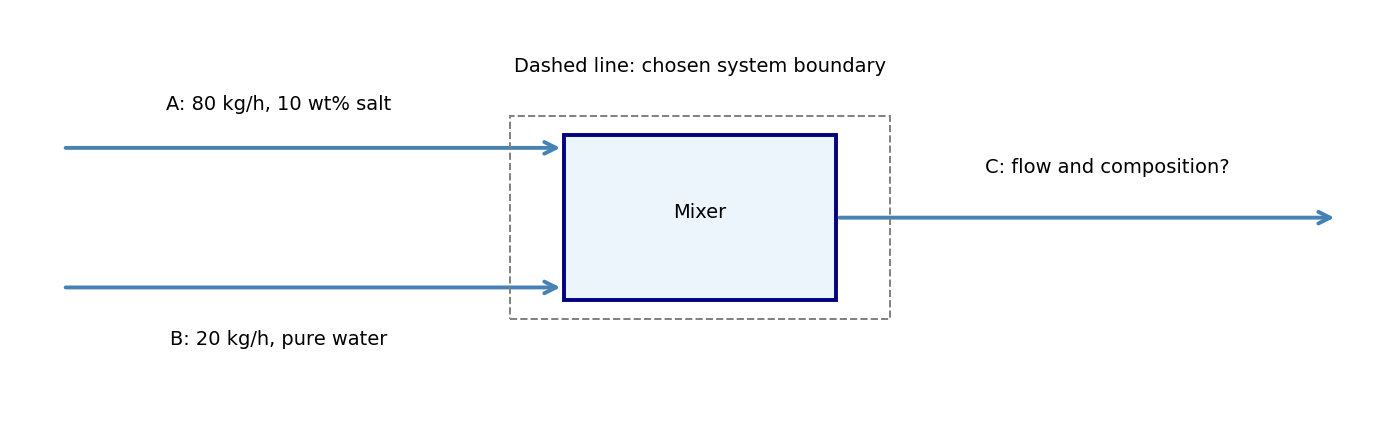

In [ ]:
#@title SETTINGS — edit values only
water_feed = 20.0 #@param {type:"number"}

In [ ]:
#@title SUPPLIED CHECK — first write the equations yourself

A,wA = 80.,.10
B,wB = water_feed,0.
C,wC = h.mix_streams(A,wA,B,wB)
print(f'Outlet C={C:.2f} kg/h; salt fraction={wC:.5f} kg/kg ({wC*100:.2f} wt%)')
print(f'Salt in={A*wA+B*wB:.2f} kg/h; salt out={C*wC:.2f} kg/h')
print(f'Total residual={A+B-C:.3e} kg/h; salt residual={A*wA+B*wB-C*wC:.3e} kg/h')
target_salt_fraction = .05  # stated 5 wt% product target, kg salt/kg solution
water_needed=A*wA/target_salt_fraction-A
print(f'Water feed for 5 wt% target: {water_needed:.2f} kg/h')

**Your answer:** Write the symbolic balance, assumptions, numbers with units, and answers to every question. A table output alone is not an answer.

## 3. Split or concentrate: choose the right balance — 35 minutes


Treat these as **two separate examples**, each fed with the original 100 kg/h,
8 wt% solution from the mixer.

**Splitter:** send 30% of the well-mixed stream to one branch. Write a total
balance and a salt balance. What are each branch's flow and concentration?
Does splitting alone produce one purer stream? Check the supplied results.

**Evaporator:** remove pure water as vapour, leaving a 20 wt% salt product.
Assume nonvolatile salt, no entrainment, no crystallization and steady operation.
Write $F=P+V$ and $Fw_F=Pw_P$ before calculating P and V. Why is a single
total balance insufficient? Check salt and water separately. Change target
product concentration to 10 wt%; does the direction of change make sense?

These are mass balances only. What is still missing to calculate evaporation
heat? Why should concentrating to a value below the feed fraction be rejected
for this pure-water-removal operation?

In [ ]:
#@title SETTINGS — edit values only
product_fraction = 0.20 #@param {type:"number"}

In [ ]:
#@title SUPPLIED CHECK — first write the equations yourself

F,wF = 100.,.08  # stated original mixer outlet: kg/h, kg salt/kg solution
split_fraction = .30  # supplied branch-one mass-flow fraction
branch1,branch2 = split_fraction*F,(1-split_fraction)*F
print(f'Splitter: {branch1:.1f} and {branch2:.1f} kg/h; both {wF*100:.1f} wt% salt')
P,V=h.evaporate(F,wF,product_fraction)
print(f'Evaporator product={P:.3f} kg/h; pure-water vapour={V:.3f} kg/h')
print(f'Salt residual={F*wF-P*product_fraction:.3e} kg/h')
print(f'Water residual={F*(1-wF)-P*(1-product_fraction)-V:.3e} kg/h')

**Your answer:** Write the symbolic balance, assumptions, numbers with units, and answers to every question. A table output alone is not an answer.

## 4. Heat a stream and mix temperatures — 40 minutes


**Water heater.** Heat 2 kg/s water from 20 to 50 °C, with constant
cp = 4180 J/(kg K), no heat loss, no phase change and no shaft work. Neglect
kinetic and potential energy changes. Write the steady energy balance, then
use $\dot Q=\dot m c_p(T_{out}-T_{in})$. Check units before computing.
Here cp means that heating 1 kg of this liquid by 1 K requires 4180 J.
Temperature differences in °C and K are equal. This example uses kg/s;
1 kg/s equals 3600 kg/h, unlike the hourly flows in the earlier examples.

Calculate heat duty in W and kW, then energy for two hours in kWh. Explain
the difference between power and energy. What changes if flow doubles or
outlet temperature is 40 °C? Are we calculating electricity or heat transferred?

**Adiabatic mixer, separate example.** Mix 0.5 kg/s water at 80 °C with
1.5 kg/s water at 20 °C. Write the total mass balance and energy balance
using the same temperature reference and constant cp for both streams. Find
the outlet temperature. Why is the simple arithmetic mean incorrect here?
Explain why outlet temperature must lie between the inlet temperatures.

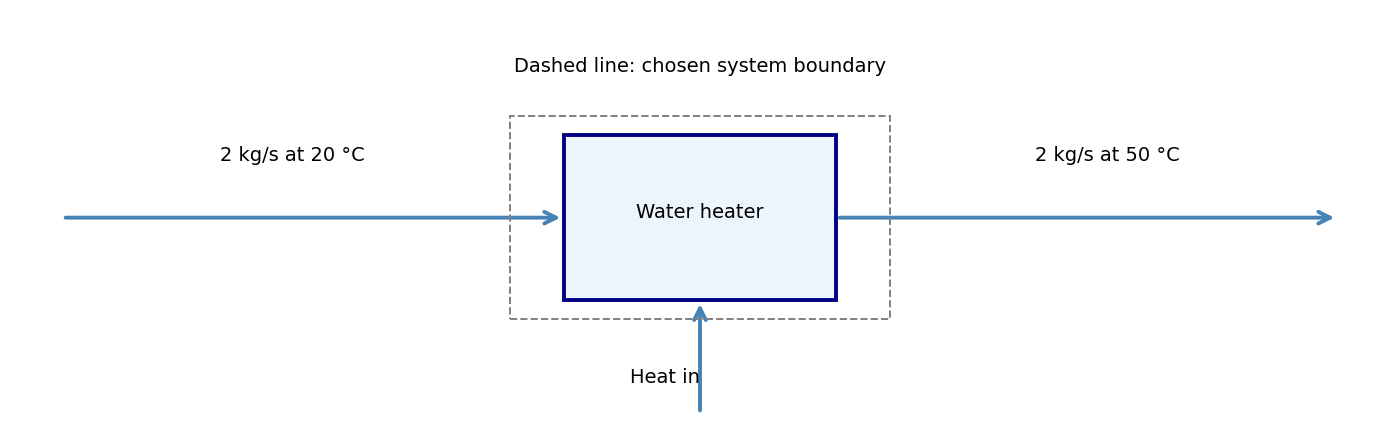

In [ ]:
#@title SETTINGS — edit values only
heated_flow = 2.0 #@param {type:"number"}
inlet_temperature = 20.0 #@param {type:"number"}
target_temperature = 50.0 #@param {type:"number"}

In [ ]:
#@title SUPPLIED CHECK — first write the equations yourself

water_cp = 4180.0  # supplied constant specific heat capacity, J/(kg K)
duty=h.heating_duty(heated_flow,water_cp,inlet_temperature,target_temperature)
print(f'Heat supplied={duty:.1f} W = {duty/1000:.3f} kW')
print(f'Heat supplied over 2 hours={duty/1000*2:.3f} kWh')
mixed_temperature=h.mixing_temperature(.5,80.,1.5,20.)
print(f'Adiabatic mixed outlet: 2 kg/s at {mixed_temperature:.3f} °C')
reference=20.
energy_in=.5*water_cp*(80-reference)+1.5*water_cp*(20-reference)
energy_out=2*water_cp*(mixed_temperature-reference)
print(f'Mixer energy residual={energy_in-energy_out:.3e} W')

**Your answer:** Write the symbolic balance, assumptions, numbers with units, and answers to every question. A table output alone is not an answer.

## 5. A filling tank: when accumulation matters — 25 minutes


Take a short break within this block. Initially the tank holds 50 kg water.
Constant inflow is 2 kg/s and constant outflow is 1.5 kg/s. Maximum contents
are 400 kg. There is no level controller. Treat the tank as well-mixed; no
density change or reaction occurs.

Write $dM/dt=\dot m_{in}-\dot m_{out}$ and integrate for constant flows.
How much water is present after ten minutes? Is this steady state? When does
the tank reach capacity? Predict what happens if outflow equals inflow.
Explain why the line must not be extrapolated past overflow or emptying.
At density 1000 kg/m³, what volume corresponds to the ten-minute inventory?
The supplied plot stops at the first capacity limit, not after it.

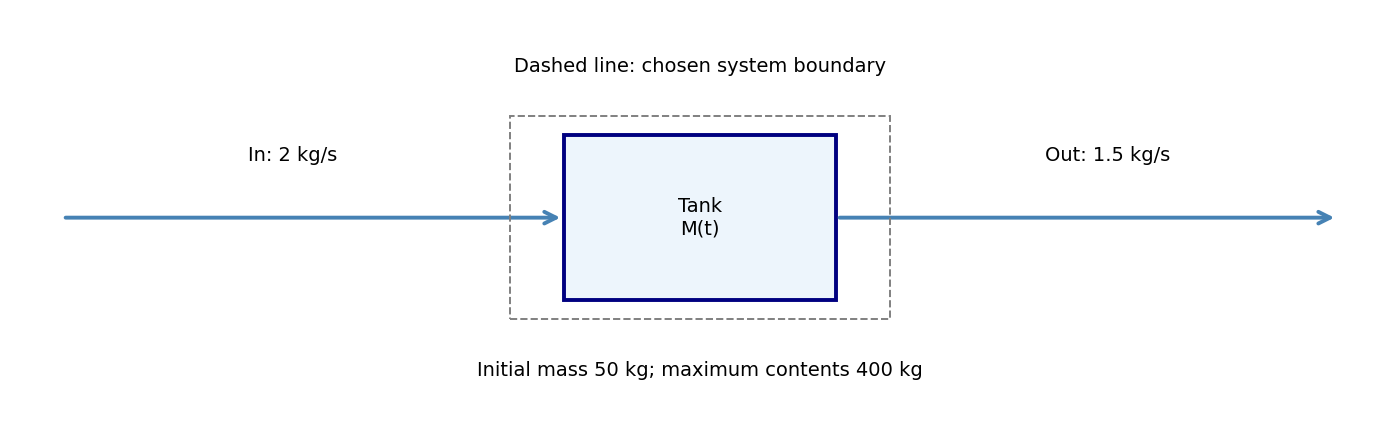

In [ ]:
#@title SETTINGS — edit values only
tank_outflow = 1.5 #@param {type:"number"}

In [ ]:
#@title SUPPLIED CHECK — first write the equations yourself

initial_mass,inflow,capacity=50.,2.,400.
evaluation_seconds = 10*60  # ten-minute inventory check, converted to seconds
water_density = 1000.0  # supplied volume-conversion density, kg/m³
net=inflow-tank_outflow
limit=(capacity-initial_mass)/net if net>0 else (initial_mass/(-net) if net<0 else np.inf)
print(f'Net accumulation={net:.3f} kg/s')
if evaluation_seconds <= limit:
    mass10=float(h.tank_inventory(initial_mass,inflow,tank_outflow,evaluation_seconds))
    print(f'At 10 min: inventory={mass10:.2f} kg; volume={mass10/water_density:.3f} m³')
else:
    print('A boundary limit is reached before ten minutes; constant-flow continuation is invalid.')
print(f'First boundary limit: {limit/60:.3f} min' if np.isfinite(limit) else 'No filling/emptying boundary reached at equal flows.')
times=np.linspace(0,min(900,limit),100)
inventory=h.tank_inventory(initial_mass,inflow,tank_outflow,times)
plt.plot(times/60,inventory,label='Valid constant-flow interval')
plt.axhline(capacity,color='black',linestyle=':',label='Capacity')
plt.xlabel('Time / min'); plt.ylabel('Water inventory / kg'); plt.legend(); plt.grid(); plt.show()

**Your answer:** Write the symbolic balance, assumptions, numbers with units, and answers to every question. A table output alone is not an answer.

## 6. Explain and review — 15 minutes

Write 150–250 words answering: What is conserved? When is accumulation zero?
Why does a component balance add information? What extra information does a
heat balance need? Give one unit mistake and one physical-limit mistake to avoid.
Swap explanations with your partner and record one clarification. Restart and
run your completed notebook in order. No new Python code is required.

## Optional practice — up to three additional hours

Use the same equations and supplied cells; no new algorithms are needed.

- Make a 6 wt% mixer product from the original 80 kg/h, 10 wt% inlet. Distinguish
  total water feed from the extra water relative to the original case.
- Set evaporator product to the feed's 8 wt%. Explain the result. Then explain
  why a requested 5 wt% product is outside this operation's assumptions.
- Heat 1 kg/s water from 15 to 55 °C and calculate heat over four hours.
- Set tank outflow to 2 and then 2.5 kg/s. Identify constant inventory or
  emptying and explain why the original ten-minute prediction can fail.
- Draw a mixer followed by an evaporator. Write balances around each unit and
  around both together. Explain why the internal connecting stream cancels.